In [1]:
import pandas as pd
import matplotlib.pyplot as plt

h = pd.read_csv("../data/news_history.csv")
h["published"] = pd.to_datetime(h["published"], utc=True,
                                format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
h = h[h["published"].dt.year == 2025]

u = h.drop_duplicates(subset="link")
print("Randuri:", len(h), "| Articole unice:", len(u))
print("Date invalide:", h["published"].isna().sum())
print()
print(u.groupby("category").size().sort_values(ascending=False))

Randuri: 12587 | Articole unice: 9560
Date invalide: 0

category
politic           4800
ue                2587
fiscal            1663
banca_centrala     298
extern             113
rating              99
dtype: int64


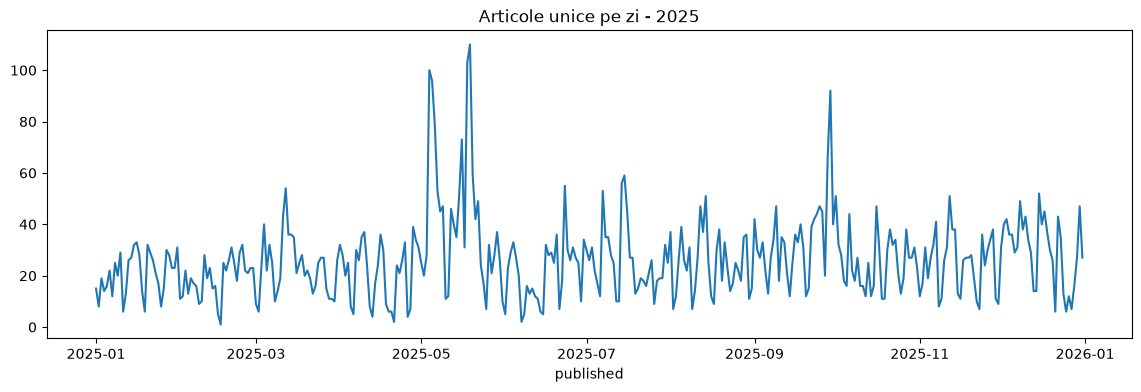

Cele mai agitate 10 zile:
published
2025-05-19    110
2025-05-18    103
2025-05-04    100
2025-05-05     96
2025-09-29     92
2025-05-06     79
2025-05-16     73
2025-09-28     66
2025-07-15     59
2025-05-20     59
dtype: int64


In [2]:
daily = u.groupby(u["published"].dt.date).size()
daily.plot(figsize=(14, 4), title="Articole unice pe zi - 2025")
plt.show()

print("Cele mai agitate 10 zile:")
print(daily.sort_values(ascending=False).head(10))

In [3]:
sources = pd.read_csv("../data/sources.csv")
counts = u["source"].value_counts()
unknown = counts[~counts.index.isin(sources["source"])]
print(f"Surse care nu sunt in sources.csv: {len(unknown)}")
print(unknown.head(30))

Surse care nu sunt in sources.csv: 473
source
RFI                  303
Ziare.com            179
Moldova 1            163
StartupCafe          137
Ziarul Bursa         134
Agerpres             126
G4Media               93
Capital.ro            92
Edupedu.ro            86
Oficiul de Știri      74
Monitorul Cluj        72
Partid AUR            66
Universul.net         65
Vot Corect            62
Q Magazine            59
Radio Moldova         57
Ziarul de Gardă       56
Bihoreanul            52
Jurnalul              48
Agrointeligența       47
StartupCafe.ro        46
Club Feroviar         46
Fanatik.ro            44
Alba24                44
Curs De Guvernare     41
Radio Chișinău        41
TV8.md                38
NewsMaker.md          35
Romania TV            35
BZI.ro                35
Name: count, dtype: int64


In [5]:
aliases = pd.read_csv("../data/sources_aliases.csv")
sources = pd.read_csv("../data/sources.csv")

alias_map = dict(zip(aliases["alias"], aliases["source"]))
u = u.copy()
u["source"] = u["source"].replace(alias_map)

kept = u[u["source"].isin(sources[sources["tier"] > 0]["source"])]
print(f"Articole inainte de lista alba: {len(u)}")
print(f"Articole pastrate: {len(kept)} ({len(kept) / len(u) * 100:.1f}%)")

Articole inainte de lista alba: 9559
Articole pastrate: 6190 (64.8%)


In [7]:
kept = kept.copy()
kept["local"] = kept["published"].dt.tz_convert("Europe/Bucharest")
print(kept["local"].head())

0   2025-01-05 10:00:00+02:00
1   2025-01-08 10:00:00+02:00
2   2025-01-01 10:00:00+02:00
3   2025-01-05 10:00:00+02:00
7   2025-01-05 10:00:00+02:00
Name: local, dtype: datetime64[us, Europe/Bucharest]


In [8]:
rates = pd.read_csv("../data/bnr_rates.csv", parse_dates=["date"])
bnr_days = rates[["date"]].sort_values("date")

kept["shifted"] = (kept["local"] + pd.Timedelta(hours=11)).dt.tz_localize(None).dt.normalize()
kept = kept.sort_values("shifted")

kept = pd.merge_asof(kept, bnr_days, left_on="shifted", right_on="date", direction="forward")
kept = kept.rename(columns={"date": "bnr_day"})

print(kept[["local", "bnr_day", "title"]].sample(8, random_state=1))

                         local    bnr_day  \
4072 2025-09-09 10:00:00+03:00 2025-09-09   
1321 2025-04-09 10:00:00+03:00 2025-04-09   
4654 2025-10-06 10:00:00+03:00 2025-10-06   
179  2025-01-15 10:00:00+02:00 2025-01-15   
2006 2025-05-13 10:00:00+03:00 2025-05-13   
5266 2025-11-14 10:00:00+02:00 2025-11-14   
2223 2025-05-19 10:00:00+03:00 2025-05-19   
45   2025-01-05 10:00:00+02:00 2025-01-08   

                                                  title  
4072  Un nou record la BNR. Este cel mai mare nivel ...  
1321  Eșec pentru primul dosar din România condus de...  
4654  Cheia împotriva inflaţiei? Investiţiile în com...  
179   190 km de piste de biciclete se construiesc de...  
2006  Alegeri prezidențiale în Polonia. Primar al Va...  
5266  Răspunsul lui Mugur Isărescu la întrebarea dac...  
2223    Leul românesc se apreciază puternic - Profit.ro  
45    Nicușor Dan, despre decizia lui Crin Antonescu...  


In [9]:
daily = kept.pivot_table(index="bnr_day", columns="category", values="link",
                         aggfunc="count", fill_value=0)
daily.loc["2025-04-25":"2025-05-25"]

category,banca_centrala,extern,fiscal,politic,rating,ue
bnr_day,,,,,,
2025-04-25,0,0,8,10,1,1
2025-04-28,0,0,5,22,0,1
2025-04-29,1,0,0,17,0,7
2025-04-30,0,0,3,6,0,5
2025-05-02,2,0,4,17,0,4
2025-05-05,2,2,1,147,0,4
2025-05-06,15,1,5,36,0,3
2025-05-07,2,1,2,31,0,6
2025-05-08,7,0,1,27,0,2


In [10]:
rates = rates.set_index("date")
eur_move = rates["EUR"].pct_change().shift(-1) * 100
check = daily.join(eur_move.rename("eur_maine_%"), how="left")
check.loc["2025-04-25":"2025-05-25", ["politic", "fiscal", "eur_maine_%"]]

,politic,fiscal,eur_maine_%
bnr_day,,,
2025-04-25,10,8,0.002009
2025-04-28,22,5,-0.002009
2025-04-29,17,0,0.002009
2025-04-30,6,3,-0.004018
2025-05-02,17,4,0.004018
2025-05-05,147,1,1.211452
2025-05-06,36,5,1.216801
2025-05-07,31,2,0.453021
2025-05-08,27,1,-0.111280


In [3]:
all_h = pd.read_csv("../data/news_history.csv")
all_h["published"] = pd.to_datetime(all_h["published"], utc=True,
                                    format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
all_u = all_h.drop_duplicates(subset="link")

print("Articole unice pe an:")
print(all_u.groupby(all_u["published"].dt.year).size())

y26 = all_u[all_u["published"].dt.year == 2026]
daily26 = y26.groupby(y26["published"].dt.date).size()
print("\nCele mai agitate 10 zile din 2026:")
print(daily26.sort_values(ascending=False).head(10))

Articole unice pe an:
published
2025     9559
2026    23648
dtype: int64

Cele mai agitate 10 zile din 2026:
published
2026-10-08    459
2026-10-13    452
2026-10-12    451
2026-10-07    449
2026-10-05    420
2026-10-09    400
2026-09-30    350
2026-10-02    343
2026-10-06    327
2026-10-14    320
dtype: int64


In [4]:
monthly = y26.groupby(y26["published"].dt.to_period("M")).size()
print("Articole pe luna, 2026:")
print(monthly)

print("\nCriza din primavara - cele mai agitate zile intre 15 aprilie si 15 mai:")
spring = daily26.loc[pd.Timestamp("2026-04-15").date():pd.Timestamp("2026-05-15").date()]
print(spring.sort_values(ascending=False).head(5))

Articole pe luna, 2026:
published
2026-01     753
2026-02     769
2026-03     732
2026-04    1865
2026-05    1947
2026-06    1895
2026-07    2540
2026-08    3787
2026-09    4609
2026-10    4751
Freq: M, dtype: int64

Criza din primavara - cele mai agitate zile intre 15 aprilie si 15 mai:
published
2026-05-05    229
2026-05-04    171
2026-04-27    168
2026-04-20    163
2026-04-28    148
dtype: int64


C:\Users\ACER NITRO 5\AppData\Local\Temp\ipykernel_18216\1942535885.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly = y26.groupby(y26["published"].dt.to_period("M")).size()


In [3]:
from pathlib import Path
import pandas as pd

out_dir = Path("../data/news_history")
out_dir.mkdir(exist_ok=True)

all_h = pd.read_csv("../data/news_history.csv")
years = pd.to_datetime(all_h["published"], utc=True,
                       format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce").dt.year

for year, part in all_h.groupby(years):
    part.to_csv(out_dir / f"{int(year)}.csv", index=False, encoding="utf-8")
    print(int(year), len(part))

print("Total:", len(all_h))

2015 1136
2016 1467
2017 1430
2018 1588
2019 2543
2020 2751
2021 3226
2022 3682
2023 4080
2024 7949
2025 12587
2026 37019
Total: 79458
